In [ ]:
#wrute an equilibrium calculator for the reaction A + B <=> C, where the initial concentrations of A and B are both 0.5 mol/L. The user will input t
#Write a Python program prompt for the dilute-phase reaction (A+B\rightleftharpoons C). Initially, ([A]_0=[B]_0=0.5\ \mathrm{mol/L}) and ([C]_0=0). The program should ask the user to enter (K_c), display the input and converted value types, and handle non-numeric or non-positive values without crashing. For valid (K_c), calculate and display the quadratic coefficients, discriminant, and both roots. Select the physically meaningful root where (0\leq x\leq0.5), calculate the equilibrium concentrations and limiting-reactant conversion, then classify the conversion as high (at least 70%), moderate (at least 40%), or low. Test with (K_c=6), (K_c=0.5), and (K_c=-2).

import math

raw_kc = input("Enter the equilibrium constant Kc: ")

print("Raw input:", raw_kc)
print("Type of raw input:", type(raw_kc))

try:
    kc = float(raw_kc)
except ValueError:
    print("Invalid input: please enter a number.")
else:
    print("Converted Kc:", kc)
    print("Type of converted value:", type(kc))

    if not math.isfinite(kc) or kc <= 0:
        print("Invalid Kc: it must be a positive number.")
    else:
        # The equilibrium equation is:
        # Kc*x^2 - (Kc + 1)*x + 0.25*Kc = 0
        a = kc
        b = -(kc + 1)
        c = 0.25 * kc

        discriminant = b**2 - 4 * a * c

        print(f"a = {a:.3f}")
        print(f"b = {b:.3f}")
        print(f"c = {c:.3f}")
        print(f"Discriminant = {discriminant:.3f}")

        root_1 = (-b + math.sqrt(discriminant)) / (2 * a)
        root_2 = (-b - math.sqrt(discriminant)) / (2 * a)

        print(f"Root 1 = {root_1:.3f}")
        print(f"Root 2 = {root_2:.3f}")

        # x must be between 0 and the initial concentration of A and B.
        valid_roots = [
            root for root in (root_1, root_2)
            if 0 <= root <= 0.5
        ]

        if len(valid_roots) == 0:
            print("No physically meaningful root was found.")
        else:
            x = valid_roots[0]

            equilibrium_a = 0.5 - x
            equilibrium_b = 0.5 - x
            equilibrium_c = x

            conversion = (x / 0.5) * 100

            print(f"Selected x = {x:.3f} mol/L")
            print(f"Equilibrium [A] = {equilibrium_a:.3f} mol/L")
            print(f"Equilibrium [B] = {equilibrium_b:.3f} mol/L")
            print(f"Equilibrium [C] = {equilibrium_c:.3f} mol/L")
            print(f"Limiting-reactant conversion = {conversion:.2f}%")

            if conversion >= 70:
                print("Conversion classification: High")
            elif conversion >= 40:
                print("Conversion classification: Moderate")
            else:
                print("Conversion classification: Low")



Raw input: 56
Type of raw input: <class 'str'>
Converted Kc: 56.0
Type of converted value: <class 'float'>
a = 56.000
b = -57.000
c = 14.000
Discriminant = 113.000
Root 1 = 0.604
Root 2 = 0.414
Selected x = 0.414 mol/L
Equilibrium [A] = 0.086 mol/L
Equilibrium [B] = 0.086 mol/L
Equilibrium [C] = 0.414 mol/L
Limiting-reactant conversion = 82.80%
Conversion classification: High


In [ ]:
#write batch reactor simulation for a first order reaction A -> B, where the initial concentration of A is 1.0 mol/L, the rate constant is 0.12 min^-1, and the simulation time is 5 minutes. The user will input the time step for the simulation. 
import math
#write a Python program  prompt that simulates a batch reactor for a first-order reaction A -> B. The program should ask the user to input the time step for the simulation, and then use the Euler method to calculate the concentration of A over time. The program should also calculate the exact concentration of A at the end of the simulation and compare it with the Euler method result, displaying the absolute error. Additionally, the program should simulate until 70% conversion or 100 minutes, whichever comes first, and display the final concentration and conversion. 
initial_concentration = 1.0
rate_constant = 0.12
time_step = 0.5
simulation_time = 5.0

# Euler simulation using a for loop
concentration = initial_concentration
time = 0.0
number_of_steps = int(simulation_time / time_step)

print("Euler method")
print(f"{'Time (min)':>12} {'Concentration (mol/L)':>24}")
print(f"{time:12.1f} {concentration:24.4f}")

for step in range(number_of_steps):
    concentration = concentration * (1 - rate_constant * time_step)
    time = time + time_step
    print(f"{time:12.1f} {concentration:24.4f}")

euler_concentration = concentration
exact_concentration = initial_concentration * math.exp(
    -rate_constant * simulation_time
)
absolute_error = abs(euler_concentration - exact_concentration)

print(f"\nExact concentration at 5 min: {exact_concentration:.6f} mol/L")
print(f"Absolute error: {absolute_error:.6f} mol/L")

# Euler simulation until 70% conversion or 100 minutes
concentration = initial_concentration
time = 0.0
conversion = 0.0

while conversion < 70 and time < 100:
    concentration = concentration * (1 - rate_constant * time_step)
    time = time + time_step
    conversion = (
        (initial_concentration - concentration) / initial_concentration
    ) * 100

print(f"\nTime needed: {time:.1f} min")
print(f"Final concentration: {concentration:.4f} mol/L")
print(f"Final conversion: {conversion:.2f}%")

Euler method
  Time (min)    Concentration (mol/L)
         0.0                   1.0000
         0.5                   0.9400
         1.0                   0.8836
         1.5                   0.8306
         2.0                   0.7807
         2.5                   0.7339
         3.0                   0.6899
         3.5                   0.6485
         4.0                   0.6096
         4.5                   0.5730
         5.0                   0.5386

Exact concentration at 5 min: 0.548812 mol/L
Absolute error: 0.010197 mol/L

Time needed: 10.0 min
Final concentration: 0.2901 mol/L
Final conversion: 70.99%


In [12]:
#write a program that prompts the user to enter a storage-tank lot code, and then counts the number of digits in the lot code and calculates the sum of those digits. If the lot code is empty, the program should print a message indicating that the lot code is empty. If the lot code contains no digits, the program should print a message indicating that there are no digits in the lot code. Otherwise, the program should print the number of digits and the sum of those digits. 
lot_code = input("Enter a storage-tank lot code: ")
#76
#  write a program that prompts the user to enter a storage-tank lot code, and then counts the number of digits in the lot code and calculates the sum of those digits. If the lot code is empty, the program should print a message indicating that the lot code is empty. If the lot code contains no digits, the program should print a message indicating that there are no digits in the lot code. Otherwise, the program should print the number of digits and the sum of those digits.    
if lot_code.strip() == "":
    print("The lot code is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in lot_code:
        if character in "0123456789":
            digit_count = digit_count + 1
            digit_sum = digit_sum + int(character)

    if digit_count == 0:
        print("The lot code contains no digits.")
    else:
        print("Number of digits:", digit_count)
        print("Sum of digits:", digit_sum)

Number of digits: 2
Sum of digits: 11


In [16]:
#write a program that calculates the number of possible blends for a given number of ingredients (n) and the number of ingredients to choose (r). The program should use the combination formula nCr = n! / (r! * (n - r)!) to calculate the number of possible blends. The program should prompt the user to enter the values of n and r, and then print the result. If the user enters invalid values (e.g., negative numbers or r greater than n), the program should print an error message.    
#write a prompt that calculates the number of possible blends for a given number of ingredients (n) and the number of ingredients to choose (r). The program should use the combination formula nCr = n! / (r! * (n - r)!) to calculate the number of possible blends. The program should prompt the user to enter the values of n and r, and then print the result. If the user enters invalid values (e.g., negative numbers or r greater than n), the program should print an error message. 
def factorial(number):

    if number < 0:
        raise ValueError("Factorial is not defined for negative numbers.")

    if number == 0:
        return 1

    return number * factorial(number - 1)


def combination(n, r):
    if n < 0 or r < 0:
        raise ValueError("n and r must not be negative.")

    if r > n:
        raise ValueError("r cannot be greater than n.")

    return factorial(n) // (factorial(r) * factorial(n - r))


try:
    blends = combination(8, 4)
    print("Number of possible blends for n=8 and r=4:", blends)
except ValueError as error:
    print("Invalid input:", error)

try:
    blends = combination(3, 5)
    print("Number of possible blends for n=3 and r=5:", blends)
except ValueError as error:
    print("Invalid input for n=3 and r=5:", error)



Number of possible blends for n=8 and r=4: 70
Invalid input for n=3 and r=5: r cannot be greater than n.


In [18]:
 #write the Fibonacci numbers using both iterative and recursive methods. The program should calculate the first n Fibonacci numbers, where n is a positive integer provided by the user. The program should then print the results from both methods and verify that they are the same. Additionally, the program should display a table with the reading number, corresponding Fibonacci number, and time in minutes (calculated as Fibonacci number multiplied by 3).    
#write the prompt which tells the user to enter a positive integer n, and then calculates the first n Fibonacci numbers using both iterative and recursive methods. The program should print the results from both methods and verify that they are the same. Additionally, the program should display a table with the reading number, corresponding Fibonacci number, and time in minutes (calculated as Fibonacci number multiplied by 3).   
def fib_iter(n):
    if n < 0:
        raise ValueError("n must not be negative.")

    fibonacci_numbers = []
    first = 0
    second = 1

    for _ in range(n):
        fibonacci_numbers.append(first)
        first, second = second, first + second

    return fibonacci_numbers


def fib_rec(k):
    if k < 0:
        raise ValueError("k must not be negative.")

    if k == 0:
        return 0
    if k == 1:
        return 1

    return fib_rec(k - 1) + fib_rec(k - 2)


number_of_readings = 8
iterative_numbers = fib_iter(number_of_readings)
recursive_numbers = [
    fib_rec(reading_index)
    for reading_index in range(number_of_readings)
]

print("Do the iterative and recursive results agree?",
      iterative_numbers == recursive_numbers)

print(f"{'Reading no.':>12} {'Fibonacci number':>18} {'Time (min)':>12}")

for index, fibonacci_number in enumerate(iterative_numbers, start=1):
    time_minutes = fibonacci_number * 3
    print(f"{index:12} {fibonacci_number:18} {time_minutes:12}")

Do the iterative and recursive results agree? True
 Reading no.   Fibonacci number   Time (min)
           1                  0            0
           2                  1            3
           3                  1            3
           4                  2            6
           5                  3            9
           6                  5           15
           7                  8           24
           8                 13           39


CSV shape: (6, 3)

CSV data types:
time_min        int64
run1_mol_L    float64
run2_mol_L    float64
dtype: object

Run statistics:
      run1_mol_L  run2_mol_L
mean    0.368333    0.286667
std     0.261719    0.290356

Run 2 shows more variation based on standard deviation.


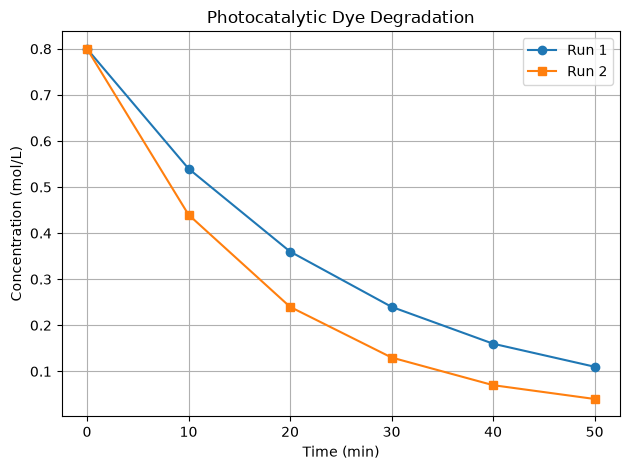


Mean value of P * V, k = 6.014 bar L


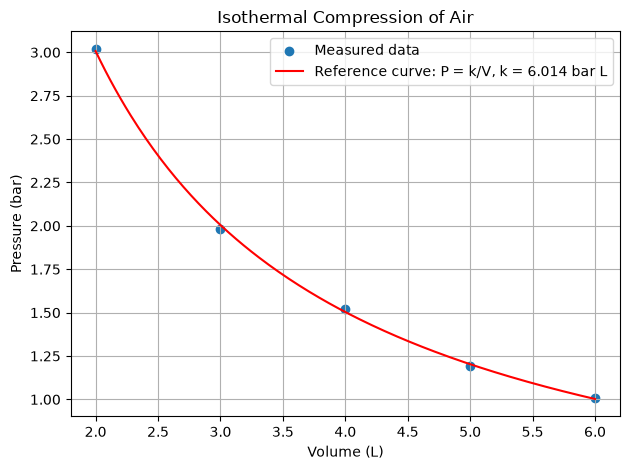

In [19]:
#plot the Fibonacci numbers using matplotlib. The x-axis should represent the reading number, and the y-axis should represent the Fibonacci number. The plot should include a title, axis labels, and a grid. Additionally, the program should save the plot as a PNG file named "fibonacci_plot.png".  
#write the prompt for matplotlib to plot the Fibonacci numbers. The x-axis should represent the reading number, and the y-axis should represent the Fibonacci number. The plot should include a title, axis labels, and a grid. Additionally, the program should save the plot as a PNG file named "fibonacci_plot.png".    
import pandas as pd
import matplotlib.pyplot as plt

# Part A: Photocatalytic degradation data
kinetics_data = {
    "time_min": [0, 10, 20, 30, 40, 50],
    "run1_mol_L": [0.80, 0.54, 0.36, 0.24, 0.16, 0.11],
    "run2_mol_L": [0.80, 0.44, 0.24, 0.13, 0.07, 0.04],
}

kinetics_df = pd.DataFrame(kinetics_data)

# Save the data in CSV and JSON formats
kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=4)

# Read the CSV file back and inspect it
kinetics_from_csv = pd.read_csv("kinetics.csv")

print("CSV shape:", kinetics_from_csv.shape)
print("\nCSV data types:")
print(kinetics_from_csv.dtypes)

# Calculate and compare the mean and standard deviation
run_statistics = kinetics_from_csv[
    ["run1_mol_L", "run2_mol_L"]
].agg(["mean", "std"])

print("\nRun statistics:")
print(run_statistics)

if run_statistics.loc["std", "run1_mol_L"] > run_statistics.loc["std", "run2_mol_L"]:
    print("\nRun 1 shows more variation based on standard deviation.")
elif run_statistics.loc["std", "run2_mol_L"] > run_statistics.loc["std", "run1_mol_L"]:
    print("\nRun 2 shows more variation based on standard deviation.")
else:
    print("\nBoth runs have the same standard deviation.")

# Plot both photocatalytic degradation runs
plt.figure()
plt.plot(
    kinetics_from_csv["time_min"],
    kinetics_from_csv["run1_mol_L"],
    marker="o",
    label="Run 1",
)
plt.plot(
    kinetics_from_csv["time_min"],
    kinetics_from_csv["run2_mol_L"],
    marker="s",
    label="Run 2",
)

plt.title("Photocatalytic Dye Degradation")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Part B: Isothermal compression of air
volume_L = np.array([2, 3, 4, 5, 6], dtype=float)
pressure_bar = np.array([3.02, 1.98, 1.52, 1.19, 1.01], dtype=float)

# Calculate the mean of P * V
pv_values = pressure_bar * volume_L
k = np.mean(pv_values)

print(f"\nMean value of P * V, k = {k:.3f} bar L")

# Generate points for the reference curve P = k / V
smooth_volume_L = np.linspace(volume_L.min(), volume_L.max(), 200)
reference_pressure_bar = k / smooth_volume_L

plt.figure()
plt.scatter(
    volume_L,
    pressure_bar,
    label="Measured data",
)
plt.plot(
    smooth_volume_L,
    reference_pressure_bar,
    color="red",
    label=f"Reference curve: P = k/V, k = {k:.3f} bar L",
)

plt.title("Isothermal Compression of Air")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()